In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt
import pickle
import time
from sklearn.metrics import accuracy_score
from funciones import frente_pareto2

In [2]:
X_train_np = np.load('X_train_750k_8020.npy')
y_train_np = np.load('y_train_750k_8020.npy')


nombres_columnas = [f"var_{i}" for i in range(X_train_np.shape[1])]
X_train = pd.DataFrame(X_train_np, columns=nombres_columnas)
y_train = pd.Series(y_train_np.ravel())

In [3]:
# cargar datos de validacion
X_validacion_np = np.load('validation_data.npy', mmap_mode='r')
with open('validation_data.npy', 'rb') as f:
    _ = np.load(f) # Salto de X
    y_validacion_np = np.load(f).ravel()

X_val = pd.DataFrame(X_validacion_np, columns=nombres_columnas)
y_val = pd.Series(y_validacion_np)

In [4]:
len(y_val)


731273

In [5]:
#import numpy as np
#import pandas as pd
#import pickle

# 1. Cargar los nombres REALES de las variables desde tu archivo .pkl

#with open("nombre_variables_b_flavor.pkl", "rb") as archivo:
 #   diccionario_nombres = pickle.load(archivo)

# Extraer explícitamente la lista de las 190 características
#nombres_reales_columnas = diccionario_nombres['nombre_caracteristicas']

# 2. Crear el DataFrame usando los nombres reales en lugar de los genéricos
# X_train = pd.DataFrame(X_train_np, columns=nombres_reales_columnas)
# y_train = pd.Series(y_train_np.ravel())

#print(f"Datos cargados con nombres reales. Total de variables: {len(X_train.columns)}")

# 3. Obtener las 50 variables más correlacionadas con el objetivo (Spearman)
#corr_target = X_train.corrwith(y_train, method='spearman').abs().sort_values(ascending=False)
#top_50_nombres = corr_target.head(190).index

# 4. Calcular la matriz de correlación entre estas 50 variables
#matriz_corr_50 = X_train[top_50_nombres].corr(method='spearman').abs()

# 5. Extraer solo el triángulo superior de la matriz
#mascara_triangulo_superior = np.triu(np.ones(matriz_corr_50.shape), k=1).astype(bool)
#matriz_limpia = matriz_corr_50.where(mascara_triangulo_superior)

# 6. Apilar, ordenar y tomar las 10 correlaciones más altas
#top_10_correlaciones = matriz_limpia.unstack().dropna().sort_values(ascending=False).head(10)

# 7. Imprimir los resultados
#print("\nLas 10 correlaciones (Spearman) más grandes entre el top 50 de variables:")
#print("-" * 70)
#for i, (var2, var1) in enumerate(top_10_correlaciones.index):
#    valor_corr = top_10_correlaciones.loc[(var2, var1)]
#    print(f"{i+1:2d}. {var1:<25} <--->   {var2:<25} : {valor_corr:.4f}")
#print("-" * 70)

Generaciones completadas: 200


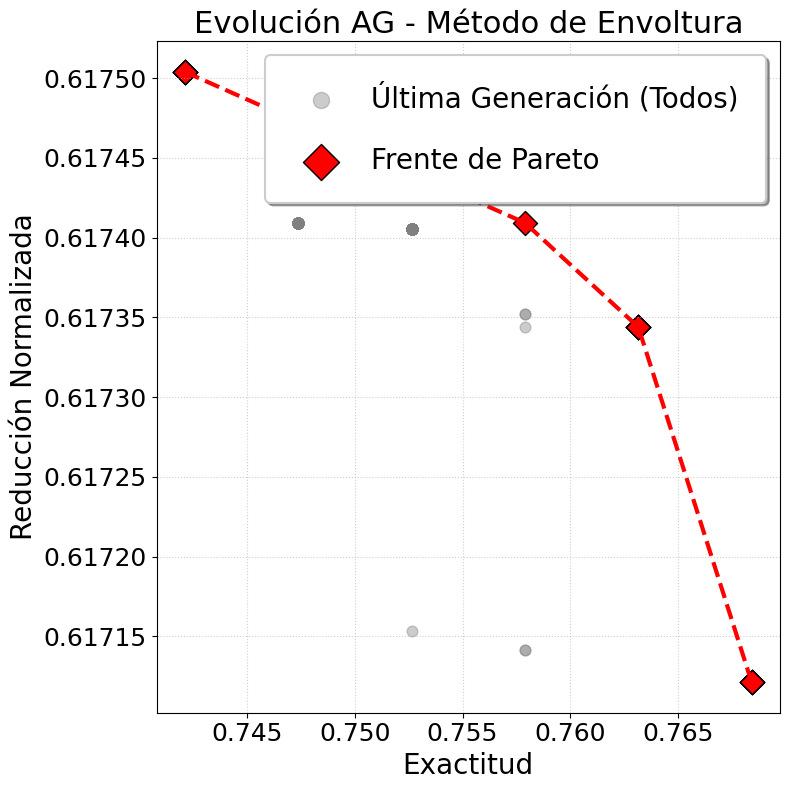

Datos del Frente de Pareto:
[{'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 44, 'exactitud': np.float64(0.6171213333333333)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, {'num_vars': 45, 'exactitud': np.float64(0.617344)}, 

In [6]:
import pygad

# Cargar la instancia del algoritmo genetico
# Nota: No es necesario poner la extensión .pkl, PyGAD la busca automáticamente
instancia_recuperada = pygad.load("instancia_750k_wrapped_lgb")

# 2. Verificar que se cargó correctamente (opcional)
print(f"Generaciones completadas: {instancia_recuperada.generations_completed}")

# 3. Pasar la instancia importada a tu función
datos_pareto = frente_pareto2(
    instancia=instancia_recuperada, 
    titulo_grafico="Evolución AG - Método de Envoltura", 
    titulo_eje_x="Exactitud", 
    titulo_eje_y="Reducción Normalizada"
)

# 4. Ver los datos extraídos
print("Datos del Frente de Pareto:")
print(datos_pareto)

In [7]:
#instancia_recuperada = pygad.load("instancia_750k_wrapped_lgb") 

#print("Extrayendo Frente de Pareto...")
#pareto_front_pygad = frente_pareto2(
#    instancia=instancia_recuperada, 
#    titulo_grafico="Frente de Pareto (AG LightGBM)", 
#    titulo_eje_x="Exactitud", 
#    titulo_eje_y="Reducción Normalizada"
#)


Datos cargados: X_train (750000, 190), y_train (750000,)
Ejecutando filtro de correlación con descarte de redundancia...
Filtro completado en 2057.14 segundos.
Total de variables seleccionadas por el filtro: 161

Iniciando evaluación contra el conjunto de Validación...
[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


...

[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/lightgbm/engine.py:177: UserWarning: Found `num_trees` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Warning] min_sum_hessian_in_leaf is set=100, min_child_weight=0.001 will be ignored. Current value: min_sum_hessian_in_leaf=100
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] num_iterations is set=500, num_trees=500 will be ignored. Current value: num_iterations=500


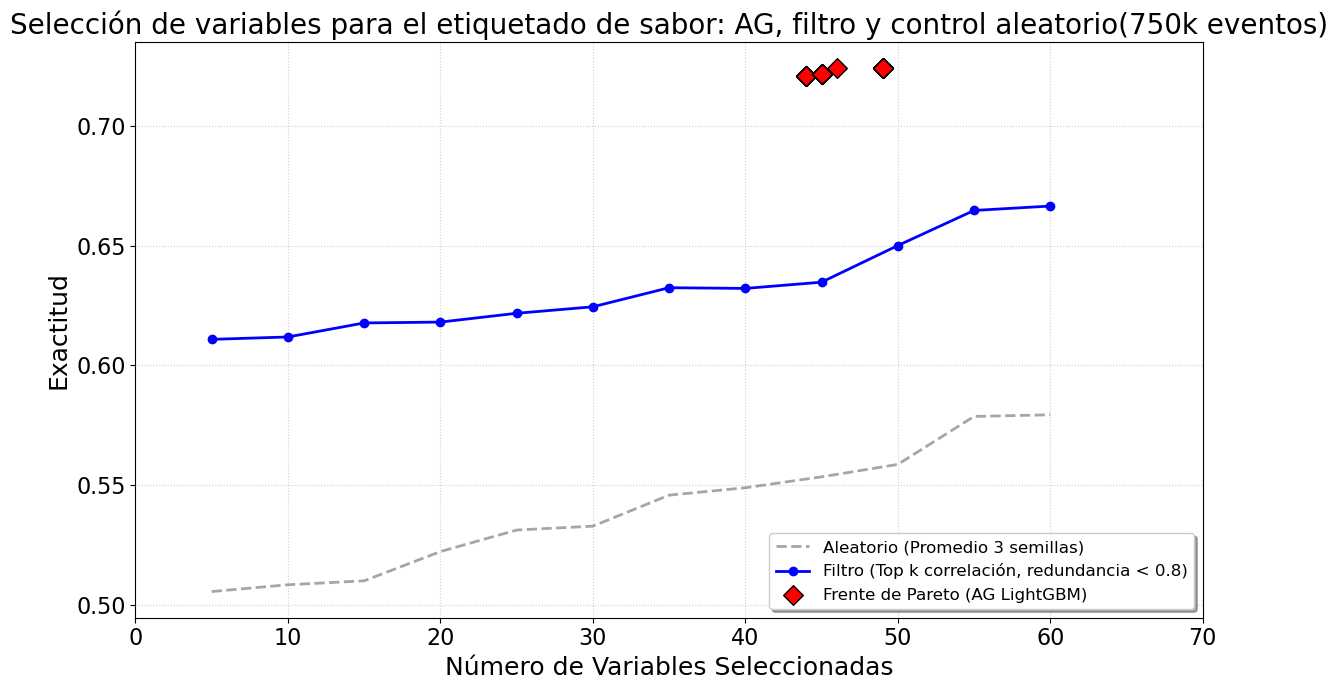

In [8]:

print(f"Datos cargados: X_train {X_train.shape}, y_train {y_train.shape}")

# Definición y ejecución del Filtro
def obtener_filtro_no_ingenuo(X, y, umbral_redundancia=0.8, max_features=190):
    #calcula el coeficiente de correlacion de cada variable respecto a la variable objetivo
    corr_target = X.corrwith(y, method='spearman').abs().sort_values(ascending=False)
    variables_seleccionadas = []
    #Calcula correlaciones entre las mismas variables
    corr_features = X.corr(method='spearman').abs()

    #ciclo que itera sobre columnas para seleccionar k columnas, y que estas 
    for col in corr_target.index:
        #Si ya se lleno la lista con el numero de variables deseado, se detiene el proceso
        if len(variables_seleccionadas) >= max_features:
            break
            
        if not variables_seleccionadas:
            variables_seleccionadas.append(col)
            continue

        #Extraemos las correlaciones de la columna actual con el resto de las variables que ya estan incluidas en la lista    
        correlaciones_existentes = corr_features.loc[col, variables_seleccionadas]

        #Si no existe un valor de correlacion mayor o igual al umbral tolerado, se almacena la variable.
        if correlaciones_existentes.max() < umbral_redundancia:
            variables_seleccionadas.append(col)
            
    return variables_seleccionadas

print("Ejecutando filtro de correlación con descarte de redundancia...")
start_time = time.time()
top_variables_limpias = obtener_filtro_no_ingenuo(X_train, y_train, umbral_redundancia=0.8)
print(f"Filtro completado en {time.time() - start_time:.2f} segundos.")
print(f"Total de variables seleccionadas por el filtro: {len(top_variables_limpias)}")


# Barrido de k y evaluación con LightGBM
k_valores = list(range(5, 65, 5))
exactitud_filtro = []
exactitud_aleatorio_promedio = []

# Configuración estándar de LightGBM (ajusta n_estimators si necesitas más velocidad)
#modelo = LGBMClassifier(random_state=42, n_jobs=-1, n_estimators=100)
modelo = LGBMClassifier(
        learning_rate=0.1,
        num_leaves=100,
        max_depth=8,            
        num_trees=500,          
        n_jobs=7,                 
    #num_threads= 16,
        min_data_in_leaf = 100,
        min_sum_hessian_in_leaf = 100,
        verbose = -1
    )

num_semillas = 3 # 

print("\nIniciando evaluación contra el conjunto de Validación...")
for k in k_valores:
    # --- Evaluación del Filtro ---
    vars_k_filtro = top_variables_limpias[:k]
    if len(vars_k_filtro) < k:
        exactitud_filtro.append(np.nan) 
    else:
        modelo.fit(X_train[vars_k_filtro], y_train)
        preds = modelo.predict(X_val[vars_k_filtro])
        exactitud_filtro.append(accuracy_score(y_val, preds))
    
    # --- Evaluación del Control Aleatorio ---
    acc_semillas = []
    for semilla in range(num_semillas):
        np.random.seed(semilla)
        vars_k_random = np.random.choice(X_train.columns, size=k, replace=False)
        modelo.fit(X_train[vars_k_random], y_train)
        preds_random = modelo.predict(X_val[vars_k_random])
        acc_semillas.append(accuracy_score(y_val, preds_random))
        
    exactitud_aleatorio_promedio.append(np.mean(acc_semillas))

# ==========================================
# 4. Extracción y Re-evaluación del Frente de Pareto en Validación
# ==========================================
print("\nCargando instancia de PyGAD y re-evaluando el Frente de Pareto...")
instancia_recuperada = pygad.load("instancia_750k_wrapped_lgb") 

# Extraemos a los individuos no dominados (el frente real) de la última generación
fitness_valores = instancia_recuperada.last_generation_fitness
pop_size = fitness_valores.shape[0]
is_pareto = np.ones(pop_size, dtype=bool)

for i in range(pop_size):
    for j in range(pop_size):
        if i != j:
            # Lógica de dominancia de Pareto
            if (fitness_valores[j, 0] >= fitness_valores[i, 0] and fitness_valores[j, 1] >= fitness_valores[i, 1]) and \
               (fitness_valores[j, 0] > fitness_valores[i, 0] or fitness_valores[j, 1] > fitness_valores[i, 1]):
                is_pareto[i] = False
                break
                
indices_pareto_reales = np.where(is_pareto)[0]

vars_pareto_val = []
auc_pareto_val = []

print("Re-entrenando y evaluando las soluciones del AG con X_val (Hold-out puro)...")
for idx in indices_pareto_reales:
    cromosoma = instancia_recuperada.population[idx]
    num_vars = int(np.sum(cromosoma))
    
    # Decodificamos el cromosoma para saber qué variables escogió
    nombres_vars_ag = [nombre for gen, nombre in zip(cromosoma, X_train.columns) if gen == 1]
    
    if len(nombres_vars_ag) > 0:
        # MAGIA AQUÍ: Entrenamos en Train, Evaluamos en Validación (X_val)
        modelo.fit(X_train[nombres_vars_ag], y_train)
        preds_ag = modelo.predict(X_val[nombres_vars_ag])
        acc_ag = accuracy_score(y_val, preds_ag)
        
        vars_pareto_val.append(num_vars)
        auc_pareto_val.append(acc_ag)

# ==========================================
# 5. Visualización
# ==========================================
plt.figure(figsize=(12, 7))

# Línea del baseline aleatorio
plt.plot(k_valores, exactitud_aleatorio_promedio, label=f'Aleatorio (Promedio {num_semillas} semillas)', 
         color='gray', linestyle='--', alpha=0.7, linewidth=2)

# Línea del filtro no ingenuo
plt.plot(k_valores, exactitud_filtro, label='Filtro (Top k correlación, redundancia < 0.8)', 
         color='blue', marker='o', markersize=6, linewidth=2)

# Puntos del Frente de Pareto RE-EVALUADOS en Validación
plt.scatter(vars_pareto_val, auc_pareto_val, label='Frente de Pareto (AG LightGBM)', 
            color='red', marker='D', s=100, zorder=5, edgecolors='black')

plt.title('Selección de variables para el etiquetado de sabor: AG, filtro y control aleatorio(750k eventos)', fontsize=20)
plt.xlabel('Número de Variables Seleccionadas', fontsize=18)
plt.ylabel('Exactitud', fontsize=18)
plt.xlim(0, 70)
plt.tick_params(axis='both', which='major', labelsize=16)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=12, loc='lower right', frameon=True, shadow=True)
plt.tight_layout()

# guardar la gráfica
plt.savefig('comparativa_filtro_vs_ag_lightgbm3.png', dpi=300)
plt.show()

In [7]:
import numpy as np
import pandas as pd
import pickle
import pygad

# --- Datos ---
X_train_np = np.load('X_train_750k_8020.npy')
y_train_np = np.load('y_train_750k_8020.npy')
nombres_columnas = [f"var_{i}" for i in range(X_train_np.shape[1])]
X_train = pd.DataFrame(X_train_np, columns=nombres_columnas)
y_train = pd.Series(y_train_np.ravel())

# --- Nombres físicos reales ---
with open('nombre_variables_b_flavor.pkl', 'rb') as f:
    nombre_columnas_reales = pickle.load(f)['nombre_caracteristicas']
mapa_nombres = dict(zip(nombres_columnas, nombre_columnas_reales))

# --- Ranking de correlación cruda ---
corr_target = X_train.corrwith(y_train, method='spearman').abs().sort_values(ascending=False)

# --- Filtro no ingenuo (para comparar también contra el filtro) ---
def obtener_filtro_no_ingenuo(X, y, umbral_redundancia=0.8, max_features=190):
    corr_target_local = X.corrwith(y, method='spearman').abs().sort_values(ascending=False)
    variables_seleccionadas = []
    corr_features = X.corr(method='spearman').abs()
    for col in corr_target_local.index:
        if len(variables_seleccionadas) >= max_features:
            break
        if not variables_seleccionadas:
            variables_seleccionadas.append(col)
            continue
        correlaciones_existentes = corr_features.loc[col, variables_seleccionadas]
        if correlaciones_existentes.max() < umbral_redundancia:
            variables_seleccionadas.append(col)
    return variables_seleccionadas

top_variables_limpias = obtener_filtro_no_ingenuo(X_train, y_train, umbral_redundancia=0.8)

# --- Frente de Pareto del AG ---
instancia_recuperada = pygad.load("instancia_750k_wrapped_lgb")
fitness_valores = instancia_recuperada.last_generation_fitness
pop_size = fitness_valores.shape[0]
is_pareto = np.ones(pop_size, dtype=bool)
for i in range(pop_size):
    for j in range(pop_size):
        if i != j:
            if (fitness_valores[j, 0] >= fitness_valores[i, 0] and fitness_valores[j, 1] >= fitness_valores[i, 1]) and \
               (fitness_valores[j, 0] > fitness_valores[i, 0] or fitness_valores[j, 1] > fitness_valores[i, 1]):
                is_pareto[i] = False
                break
indices_pareto_reales = np.where(is_pareto)[0]

# --- Comparación por cada solución del frente de Pareto del AG ---
registros = []
for idx in indices_pareto_reales:
    cromosoma = instancia_recuperada.population[idx]
    vars_ag = set(nombre for gen, nombre in zip(cromosoma, X_train.columns) if gen == 1)
    k = len(vars_ag)

    vars_top_corr_k = set(corr_target.head(k).index)
    vars_filtro_k = set(top_variables_limpias[:k])

    registros.append({
        'k': k,
        'jaccard_AG_vs_TopCorr': len(vars_ag & vars_top_corr_k) / len(vars_ag | vars_top_corr_k),
        'jaccard_AG_vs_Filtro': len(vars_ag & vars_filtro_k) / len(vars_ag | vars_filtro_k),
        '% AG dentro de TopCorr': round(100 * len(vars_ag & vars_top_corr_k) / k, 1),
        'AG_no_en_TopCorr': sorted(mapa_nombres[v] for v in (vars_ag - vars_top_corr_k)),
        'TopCorr_no_en_AG': sorted(mapa_nombres[v] for v in (vars_top_corr_k - vars_ag)),
    })

df_solapamiento = pd.DataFrame(registros).sort_values('k').reset_index(drop=True)
df_solapamiento


,k,jaccard_AG_vs_TopCorr,jaccard_AG_vs_Filtro,% AG dentro de TopCorr,AG_no_en_TopCorr,TopCorr_no_en_AG
0,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
1,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
2,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
3,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
4,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
5,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
6,44,0.189189,0.189189,31.8,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
7,45,0.184211,0.184211,31.1,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
8,45,0.184211,0.184211,31.1,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."
9,45,0.184211,0.184211,31.1,"[T10_cosTheta, T10_recoilMassSqrd, T1_dr, T1_k...","[T10_EW90, T10_charge, T10_dz, T10_elecID, T10..."


In [8]:
df_solapamiento.to_csv('solapamiento_ag_vs_correlacion.csv', index=False)
